# Regional 2D building view-factor graph

This notebook exercises the packaged OpenView workflow in three stages:

1. build two adjacent downtown Los Angeles tiles;
2. inspect `bvf_max` and directional edge scores with an interactive map;
3. run the same workflow over the full LARIAC county file.

The model is two-dimensional. Facade weights are plan lengths in metres, not vertical wall areas, and building height is not used. Install the package from the repository root with `python -m pip install -e ".[graph,viz]"` before running this notebook.

In [1]:
import os
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import pyogrio
from pyproj import Transformer
from shapely.geometry import LineString

from openviewcore.network import BVFGraphConfig, build_bvf_graph

pd.set_option("display.max_columns", 50)

## 1. Inputs and two-tile test

Change `LARIAC_PATH`, or set the `LARIAC_BUILDINGS` environment variable, on the compute machine. The test bounds cover two adjacent 2 km tiles in downtown Los Angeles and are expressed in EPSG:26911 metres. Existing completed tile partitions are reused.

In [2]:
def find_project_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the OpenView repository.")


PROJECT_ROOT = find_project_root()
LARIAC_PATH = Path(os.environ.get(
    "LARIAC_BUILDINGS",
    "/Users/adamswietek/Documents/PostDoc/data/raw_la/laraic_files/LARIAC6_Buildings_2020.gdb",
))
LARIAC_LAYER = "LARIAC6_BUILDINGS_2020"
TARGET_CRS = "EPSG:26911"
WUI_PATH = Path(os.environ.get(
    "CALFIRE_WUI", PROJECT_ROOT / "notebooks" / "eda" / "calfire_wui_la.gpkg"
))
WUI_CLASSES = ("Influence Zone", "Interface", "Intermix")
WUI_BUFFER_M = 3 * 1_609.344  # three miles in metres
WUI_SIMPLIFY_M = 25.0  # simplify the union before buffering to reduce construction cost

In [3]:
TEST_BOUNDS = (384_000.0, 3_768_000.0, 388_000.0, 3_770_000.0)
OUTPUT_ROOT = Path(os.environ.get("OPENVIEW_BVF_OUTPUT_ROOT", PROJECT_ROOT / "results"))
TEST_OUTPUT = Path(os.environ.get("OPENVIEW_BVF_TEST_OUTPUT", OUTPUT_ROOT / "bvf_two_tile_demo_bvh"))

if not LARIAC_PATH.exists():
    raise FileNotFoundError(
        f"LARIAC file not found: {LARIAC_PATH}\n"
        "Set LARIAC_PATH above or define the LARIAC_BUILDINGS environment variable."
    )

test_config = BVFGraphConfig(
    layer=LARIAC_LAYER,
    id_column="OBJECTID",
    source_id_column="BLD_ID",
    target_crs=TARGET_CRS,
    tile_size_m=2_000,
    max_distance_m=152.4,  # 500 ft
    visibility_backend="bvh",
    ray_offset_m=0.01,
    hit_tolerance_m=0.005,
    workers=1,
    resume=True,
)

test_result = build_bvf_graph(
    LARIAC_PATH,
    TEST_OUTPUT,
    config=test_config,
    bounds=TEST_BOUNDS,
    max_tiles=2,
)
test_result

2D BVF tiles: 100%|##########| 2/2 [00:00<?, ?tile/s]

BVFGraphResult(output_dir=PosixPath('/Users/adamswietek/Documents/PostDoc/openview/results/bvf_two_tile_demo_bvh'), patches_path=PosixPath('/Users/adamswietek/Documents/PostDoc/openview/results/bvf_two_tile_demo_bvh/patches'), contacts_path=PosixPath('/Users/adamswietek/Documents/PostDoc/openview/results/bvf_two_tile_demo_bvh/contacts'), building_ids_path=PosixPath('/Users/adamswietek/Documents/PostDoc/openview/results/bvf_two_tile_demo_bvh/building_ids.parquet'), patch_exchange_path=PosixPath('/Users/adamswietek/Documents/PostDoc/openview/results/bvf_two_tile_demo_bvh/patch_exchange.parquet'), building_edges_path=PosixPath('/Users/adamswietek/Documents/PostDoc/openview/results/bvf_two_tile_demo_bvh/building_edges.parquet'), building_metrics_path=PosixPath('/Users/adamswietek/Documents/PostDoc/openview/results/bvf_two_tile_demo_bvh/building_metrics.parquet'), manifest_path=PosixPath('/Users/adamswietek/Documents/PostDoc/openview/results/bvf_two_tile_demo_bvh/manifest.json'))

In [4]:
edges = pd.read_parquet(test_result.building_edges_path)
metrics = pd.read_parquet(test_result.building_metrics_path)
building_ids = pd.read_parquet(test_result.building_ids_path)
if "exchange_total_m" not in metrics:
    metrics["exchange_total_m"] = metrics["perimeter_m"] * metrics["bvf_all_edges"]

summary = pd.Series({
    "buildings": len(metrics),
    "unique building edges": len(edges),
    "contact edges": int(edges["has_contact"].sum()),
    "maximum total BVF": metrics["bvf_all_edges"].max(),
    "maximum BVF_max": metrics["bvf_max"].max(),
    "duplicate pairs": edges.duplicated(["building_i", "building_j"]).sum(),
    "decomposition error": (
        metrics["bvf_all_edges"]
        - metrics["bvf_noncontact_edges"]
        - metrics["bvf_contact_edges"]
    ).abs().max(),
})
display(summary.to_frame("value"))
display(edges.sort_values("vf_i_to_j", ascending=False).head(10))

,value
buildings,3088.0
unique building edges,22533.0
contact edges,868.0
maximum total BVF,1.0
maximum BVF_max,1.0
duplicate pairs,0.0
decomposition error,0.0


,building_i,building_j,exchange_visible_ij_m,visible_patch_pair_count,contact_i_to_j_m,contact_j_to_i_m,contact_patch_count,perimeter_i_m,perimeter_j_m,vf_i_to_j,vf_j_to_i,f_max_i_to_j,f_max_j_to_i,has_contact
22532,2230639,2230659,0.0,0,38.946656,38.946656,8,38.946656,203.908574,1.0,0.191001,1.0,1.0,True
22304,1897274,2079995,0.0,0,12.587650,12.587650,4,12.587650,192.909786,1.0,0.065251,1.0,1.0,True
22301,2231049,2231107,0.0,0,73.357853,73.357853,8,73.357853,774.622049,1.0,0.094701,1.0,1.0,True
22300,2230569,2230628,0.0,0,46.362124,46.362124,8,46.362124,489.721186,1.0,0.094670,1.0,1.0,True
22288,1897831,2077320,0.0,0,84.825927,84.825927,40,84.825927,440.357676,1.0,0.192630,1.0,1.0,True
22287,1897197,2089335,0.0,0,66.547857,66.547857,12,66.547857,598.709681,1.0,0.111152,1.0,1.0,True
22286,1896974,2077320,0.0,0,8.150558,8.150558,4,8.150558,440.357676,1.0,0.018509,1.0,1.0,True
22285,1896675,2075384,0.0,0,90.710804,90.710804,40,90.710804,1187.406835,1.0,0.076394,1.0,1.0,True
22284,1896640,2001311,0.0,0,74.346407,74.346407,40,74.346407,349.746502,1.0,0.212572,1.0,1.0,True
22283,1874431,1878061,0.0,0,25.222659,25.222659,8,25.222659,132.771349,1.0,0.189971,1.0,1.0,True


## 2. Total building exchange

The map is colored by each building's total outgoing exchange, `exchange_total_m = perimeter_m × bvf_all_edges`. This includes visible and contact exchange. Its units are metres because the current model uses 2D facade-plan lengths rather than 3D wall areas.

In [5]:
source_info = pyogrio.read_info(LARIAC_PATH, layer=LARIAC_LAYER)
to_source = Transformer.from_crs(TARGET_CRS, source_info["crs"], always_xy=True)
source_bbox = to_source.transform_bounds(*TEST_BOUNDS, densify_pts=21)

sample_buildings = pyogrio.read_dataframe(
    LARIAC_PATH,
    layer=LARIAC_LAYER,
    bbox=source_bbox,
    columns=["BLD_ID"],
    fid_as_index=True,
).to_crs(TARGET_CRS)
sample_buildings["building_id"] = sample_buildings.index.astype("int64")
sample_buildings = sample_buildings.merge(metrics, on="building_id", how="left")
sample_buildings = sample_buildings.cx[TEST_BOUNDS[0]:TEST_BOUNDS[2], TEST_BOUNDS[1]:TEST_BOUNDS[3]]
sample_buildings.head()

,BLD_ID,geometry,building_id,perimeter_m,exchange_total_m,neighbor_count,bvf_all_edges,bvf_noncontact_edges,bvf_contact_edges,bvf_max
0,484256839921,"MULTIPOLYGON (((384148.316 3768203.335, 384148...",1863702,260.040268,193.320428,15.0,0.743425,0.485212,0.258213,1.0
1,484424839842,"MULTIPOLYGON (((384189.745 3768147.619, 384179...",1863703,112.545350,109.977095,12.0,0.977180,0.234039,0.743142,1.0
2,484421840069,"MULTIPOLYGON (((384175.713 3768230.064, 384154...",1863704,152.254074,130.779884,9.0,0.858958,0.393040,0.465919,1.0
3,484211839663,"MULTIPOLYGON (((384073.949 3768082.505, 384087...",1863705,95.149878,75.487942,11.0,0.793358,0.445145,0.348213,1.0
4,484190839793,"MULTIPOLYGON (((384088.483 3768150.288, 384101...",1863706,44.682838,41.542945,5.0,0.929729,0.507633,0.422096,1.0


In [6]:
sample_buildings[["building_id", "perimeter_m", "bvf_all_edges", "exchange_total_m"]].describe()

,building_id,perimeter_m,bvf_all_edges,exchange_total_m
count,3.145000e+03,3088.000000,3088.000000,3088.000000
mean,2.066047e+06,90.830309,0.744782,65.327075
std,1.133881e+05,109.831718,0.175237,73.961242
min,1.863702e+06,2.169158,0.000000,0.000000
25%,2.001345e+06,36.066651,0.641038,24.896887
50%,2.078973e+06,54.327062,0.764501,40.186650
75%,2.159016e+06,103.984220,0.877732,81.056722
max,2.231896e+06,1336.774739,1.000000,924.702247


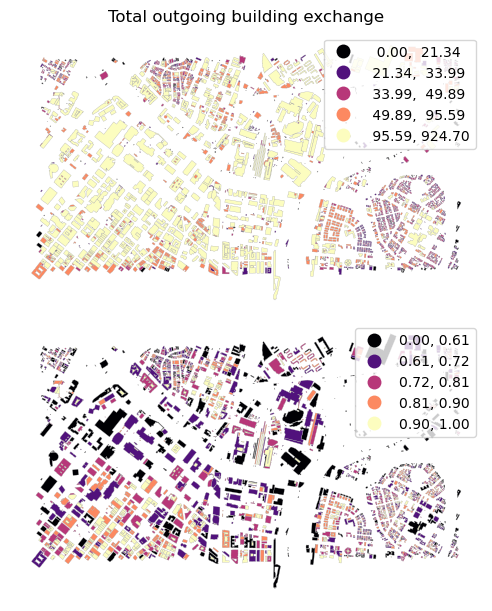

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(12, 6), constrained_layout=True)
ax = ax.flatten()
sample_buildings.plot(
    ax=ax[0],
    column="exchange_total_m",
    scheme = 'quantiles',
    cmap="magma",
    edgecolor="0.65",
    linewidth=0.2,
    legend=True,
    # legend_kwds={"label": "Total 2D building exchange [m]", "shrink": 0.75},
)
sample_buildings.plot(
    ax=ax[1],
    column="bvf_all_edges",
    scheme = 'quantiles',
    cmap="magma",
    edgecolor="0.65",
    linewidth=0.2,
    legend=True,
    # legend_kwds={"label": "Total 2D building exchange [m]", "shrink": 0.75},
)

# ax.set_aspect("equal")
ax[0].set_axis_off()
ax[1].set_axis_off()
plt.suptitle("Total outgoing building exchange")
plt.show()

## 3. Full Los Angeles County run

The regional run includes structures intersecting a three-mile buffer around the union of all three CAL FIRE WUI categories: Influence Zone, Interface, and Intermix. The categories are dissolved before simplification and buffering so overlaps and shared boundaries form one analysis geometry. Nearby out-of-scope buildings are still loaded as visibility blockers but do not become graph nodes. Set `RUN_FULL_WUI = True` only on the compute machine. Use a new output directory whenever the input, mask, or geometric parameters change. The run is resumable, so restarting the same cell skips completed tiles. Worker memory depends on local building density; begin with 4–8 workers, monitor RAM, and increase from there.

In [ ]:
RUN_FULL_WUI = True
FULL_OUTPUT = OUTPUT_ROOT / "lariac6_wui_all_3mi_bvf_2d_bvh"
FULL_WORKERS = int(os.environ.get("OPENVIEW_BVF_WORKERS", "8"))

if not WUI_PATH.exists():
    raise FileNotFoundError(f"CAL FIRE WUI layer not found: {WUI_PATH}")
wui = gpd.read_file(WUI_PATH).to_crs(TARGET_CRS)
wui_class_key = wui["WUI_DESC"].astype("string").str.strip().str.casefold()
requested_class_keys = {name.casefold() for name in WUI_CLASSES}
wui_categories = wui.loc[wui_class_key.isin(requested_class_keys)].copy()
found_class_keys = set(wui_class_key.loc[wui_categories.index].dropna())
missing_classes = [
    name for name in WUI_CLASSES if name.casefold() not in found_class_keys
]
if missing_classes:
    raise ValueError(f"Missing requested WUI categories: {missing_classes}")

# Dissolve the three categories first, then simplify and buffer that union.
wui_union = wui_categories.geometry.union_all()
wui_3mi_mask = wui_union.simplify(
    WUI_SIMPLIFY_M, preserve_topology=True
).buffer(WUI_BUFFER_M, quad_segs=4)

full_config = BVFGraphConfig(
    layer=LARIAC_LAYER,
    id_column="OBJECTID",
    source_id_column="BLD_ID",
    target_crs=TARGET_CRS,
    tile_size_m=2_000,
    max_distance_m=152.4,  # 500 ft
    visibility_backend="bvh",
    ray_offset_m=0.01,
    hit_tolerance_m=0.005,
    workers=FULL_WORKERS,
    resume=True,
)

if RUN_FULL_WUI:
    full_result = build_bvf_graph(
        LARIAC_PATH,
        FULL_OUTPUT,
        config=full_config,
        selection_mask=wui_3mi_mask,
    )
    display(pd.read_parquet(full_result.building_metrics_path).describe())
    print(f"Three-mile unioned-WUI graph written to: {full_result.output_dir}")
else:
    print("Dry run only. Set RUN_FULL_WUI = True to launch the regional build.")
    print(wui_categories["WUI_DESC"].value_counts().sort_index())
    print(f"Unioned three-mile mask bounds: {tuple(round(v, 1) for v in wui_3mi_mask.bounds)}")
    print(f"Workers: {FULL_WORKERS}; output: {FULL_OUTPUT}")

2D BVF tiles:   0%|          | 0/2045 [00:00<?, ?tile/s]


setting thread affinity failed

setting thread affinity failedsetting thread affinity failed

setting thread affinity failed
setting thread affinity failed
setting thread affinity failed
setting thread affinity failed


setting thread affinity failed
setting thread affinity failedWarning: setting thread affinity failed

setting thread affinity failed
setting thread affinity failed
setting thread affinity failed


setting thread affinity failed
setting thread affinity failed


setting thread affinity failed
setting thread affinity failed
setting thread affinity failed
setting thread affinity failed
setting thread affinity failed
setting thread affinity failed

setting thread affinity failed
setting thread affinity failed
setting thread affinity failed
setting thread affinity failed

setting thread affinity failed

setting thread affinity failed

setting thread affinity failed
setting thread affinity failed
setting thread affinity failed
setting thread affinity failed



setting thread 

In [10]:
# Works even if the kernel was restarted after the run completed
result_dir = (
    full_result.output_dir
    if "full_result" in globals()
    else FULL_OUTPUT
)

metrics = pd.read_parquet(result_dir / "building_metrics.parquet")

# Read only LARIAC buildings intersecting the three-mile unioned-WUI mask
source_crs = pyogrio.read_info(
    LARIAC_PATH,
    layer=LARIAC_LAYER,
)["crs"]

mask_source = gpd.GeoSeries(
    [wui_3mi_mask],
    crs=TARGET_CRS,
).to_crs(source_crs).iloc[0]

gdf = pyogrio.read_dataframe(
    LARIAC_PATH,
    layer=LARIAC_LAYER,
    mask=mask_source,
    columns=["BLD_ID"],
    fid_as_index=True,
).to_crs(TARGET_CRS)

# The graph's building_id corresponds to the source feature/FID index
gdf["building_id"] = gdf.index.astype("int64")
gdf = gdf.merge(metrics, on="building_id", how="inner")

print(f"{len(gdf):,} mapped buildings")

769,352 mapped buildings


<Axes: xlabel='bvf_all_edges', ylabel='Proportion'>

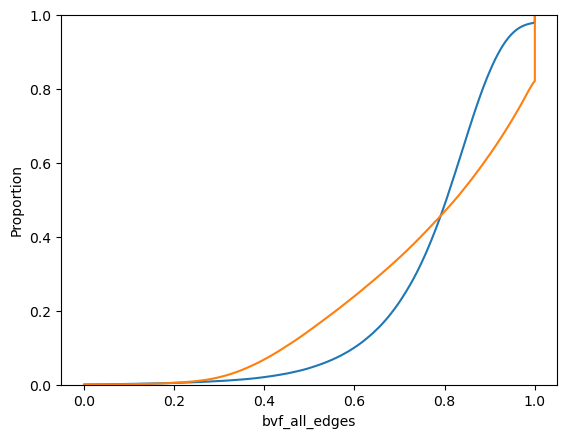

In [25]:
import seaborn as sns

sns.ecdfplot(data=gdf, x="bvf_all_edges", stat="proportion", label = 'BVF')
sns.ecdfplot(data=gdf, x="bvf_max", stat="proportion", label = 'BVF_max')

In [ ]:
smp = gdf.sample(10_000)


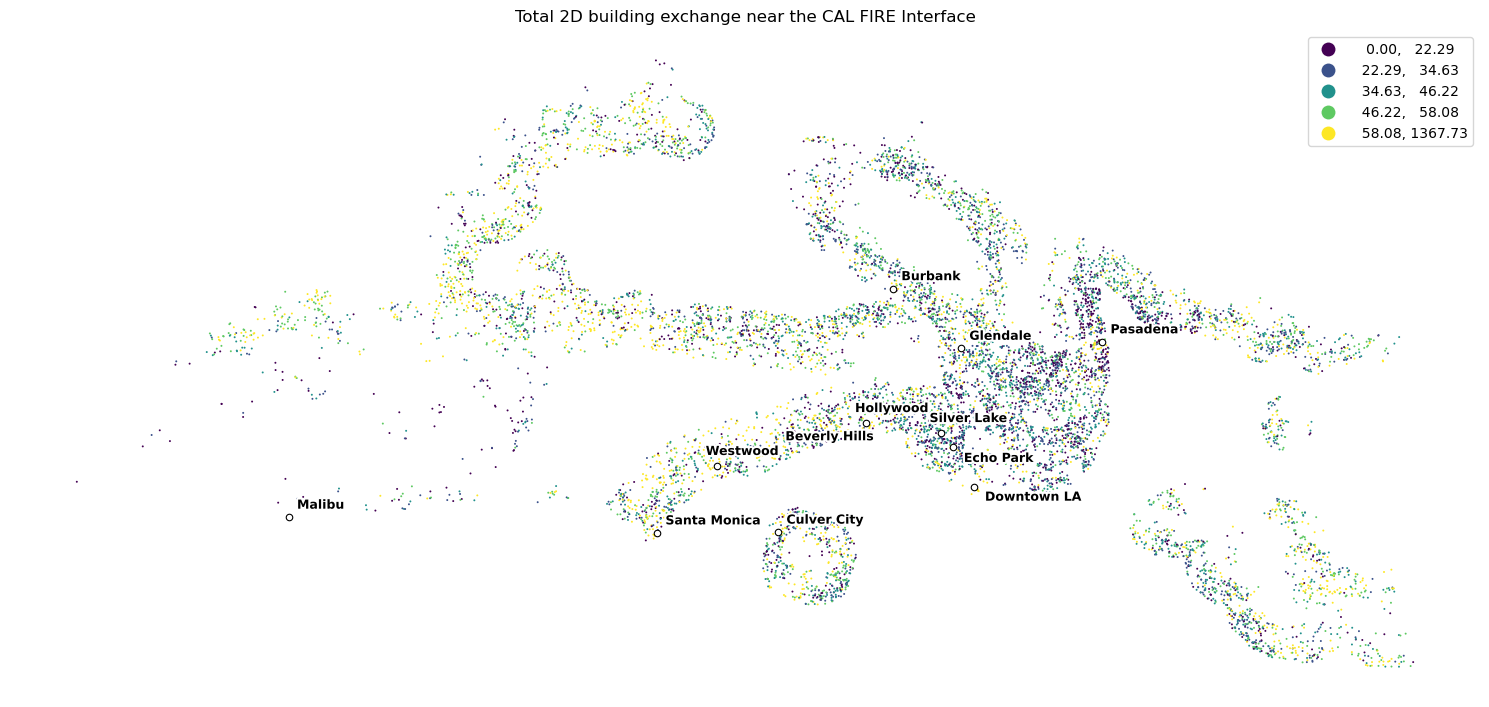

In [24]:
from matplotlib import patheffects
from shapely.geometry import Point

# Geographic reference points; these are map labels, not graph nodes.
place_xy = {
    'Pasadena': (-118.1445, 34.1478),
    'Silver Lake': (-118.2702, 34.0869),
    'Echo Park': (-118.2606, 34.0782),
    'Beverly Hills': (-118.4004, 34.0736),
    'Glendale': (-118.2551, 34.1425),
    'Downtown LA': (-118.2437, 34.0522),
    'Hollywood': (-118.3287, 34.0928),
    'Santa Monica': (-118.4912, 34.0195),
    'Westwood': (-118.4452, 34.0635),
    'Culver City': (-118.3965, 34.0211),
    'Burbank': (-118.3090, 34.1808),
    'Long Beach': (-118.1937, 33.7701),
    'Malibu': (-118.7798, 34.0259),
}
label_offsets = {
    'Silver Lake': (-8, 8), 'Echo Park': (8, -11),
    'Downtown LA': (8, -10), 'Hollywood': (-8, 8),
    'Westwood': (-8, 8), 'Beverly Hills': (8, 8),
}
places = gpd.GeoDataFrame(
    {'place': list(place_xy)},
    geometry=[Point(xy) for xy in place_xy.values()],
    crs='EPSG:4326',
).to_crs(smp.crs)

# Do not let an out-of-frame label expand the plotted map extent.
xmin, ymin, xmax, ymax = smp.total_bounds
places = places.cx[xmin:xmax, ymin:ymax]

fig, ax = plt.subplots(figsize=(15, 12))
smp_points = smp.copy()
smp_points.geometry = smp_points.geometry.centroid
smp_points.plot(
    ax=ax, column='exchange_total_m', markersize=2, scheme='quantiles',
    cmap='viridis', edgecolor='none', legend=True,
)
places.plot(ax=ax, color='white', edgecolor='black', markersize=22, linewidth=0.8, zorder=4)
for row in places.itertuples():
    dx, dy = label_offsets.get(row.place, (6, 6))
    annotation = ax.annotate(
        row.place, (row.geometry.x, row.geometry.y), xytext=(dx, dy),
        textcoords='offset points', fontsize=9, weight='bold', zorder=5,
    )
    annotation.set_path_effects([patheffects.withStroke(linewidth=3, foreground='white')])
ax.set_title('Total 2D building exchange within 3 miles of CAL FIRE WUI')
ax.set_axis_off()
plt.tight_layout()
plt.show()